Dataset Shape: (732, 12)

First 5 rows:
   Unnamed: 0                              College_Name       State    UG_fee  \
0           0    Indian Institute of Technology Madras   Tamil nadu     75116   
1           1  College of Engineering, Anna University   Tamil nadu     50000   
2           2              NIT Trichy, Tiruchirappalli   Tamil nadu  1,49,250   
3           3          Vellore Institute of Technology   Tamil nadu  1,98,000   
4           4     SRM Engineering College, Kanchipuram   Tamil nadu  2,60,000   

     PG_fee Rating Academic Accommodation Faculty Infrastructure Placement  \
0     23070    8.7        9           7.9     8.7            8.8       8.8   
1     50000    8.4      8.7           7.7     8.1            8.7       8.3   
2     99250    8.5      8.6           7.8     8.2            8.7       8.8   
3  1,83,000    8.3      8.3             8     7.8            8.9       8.5   
4  1,70,000    7.2      6.5           6.6     6.9            7.6       7.1   

  So

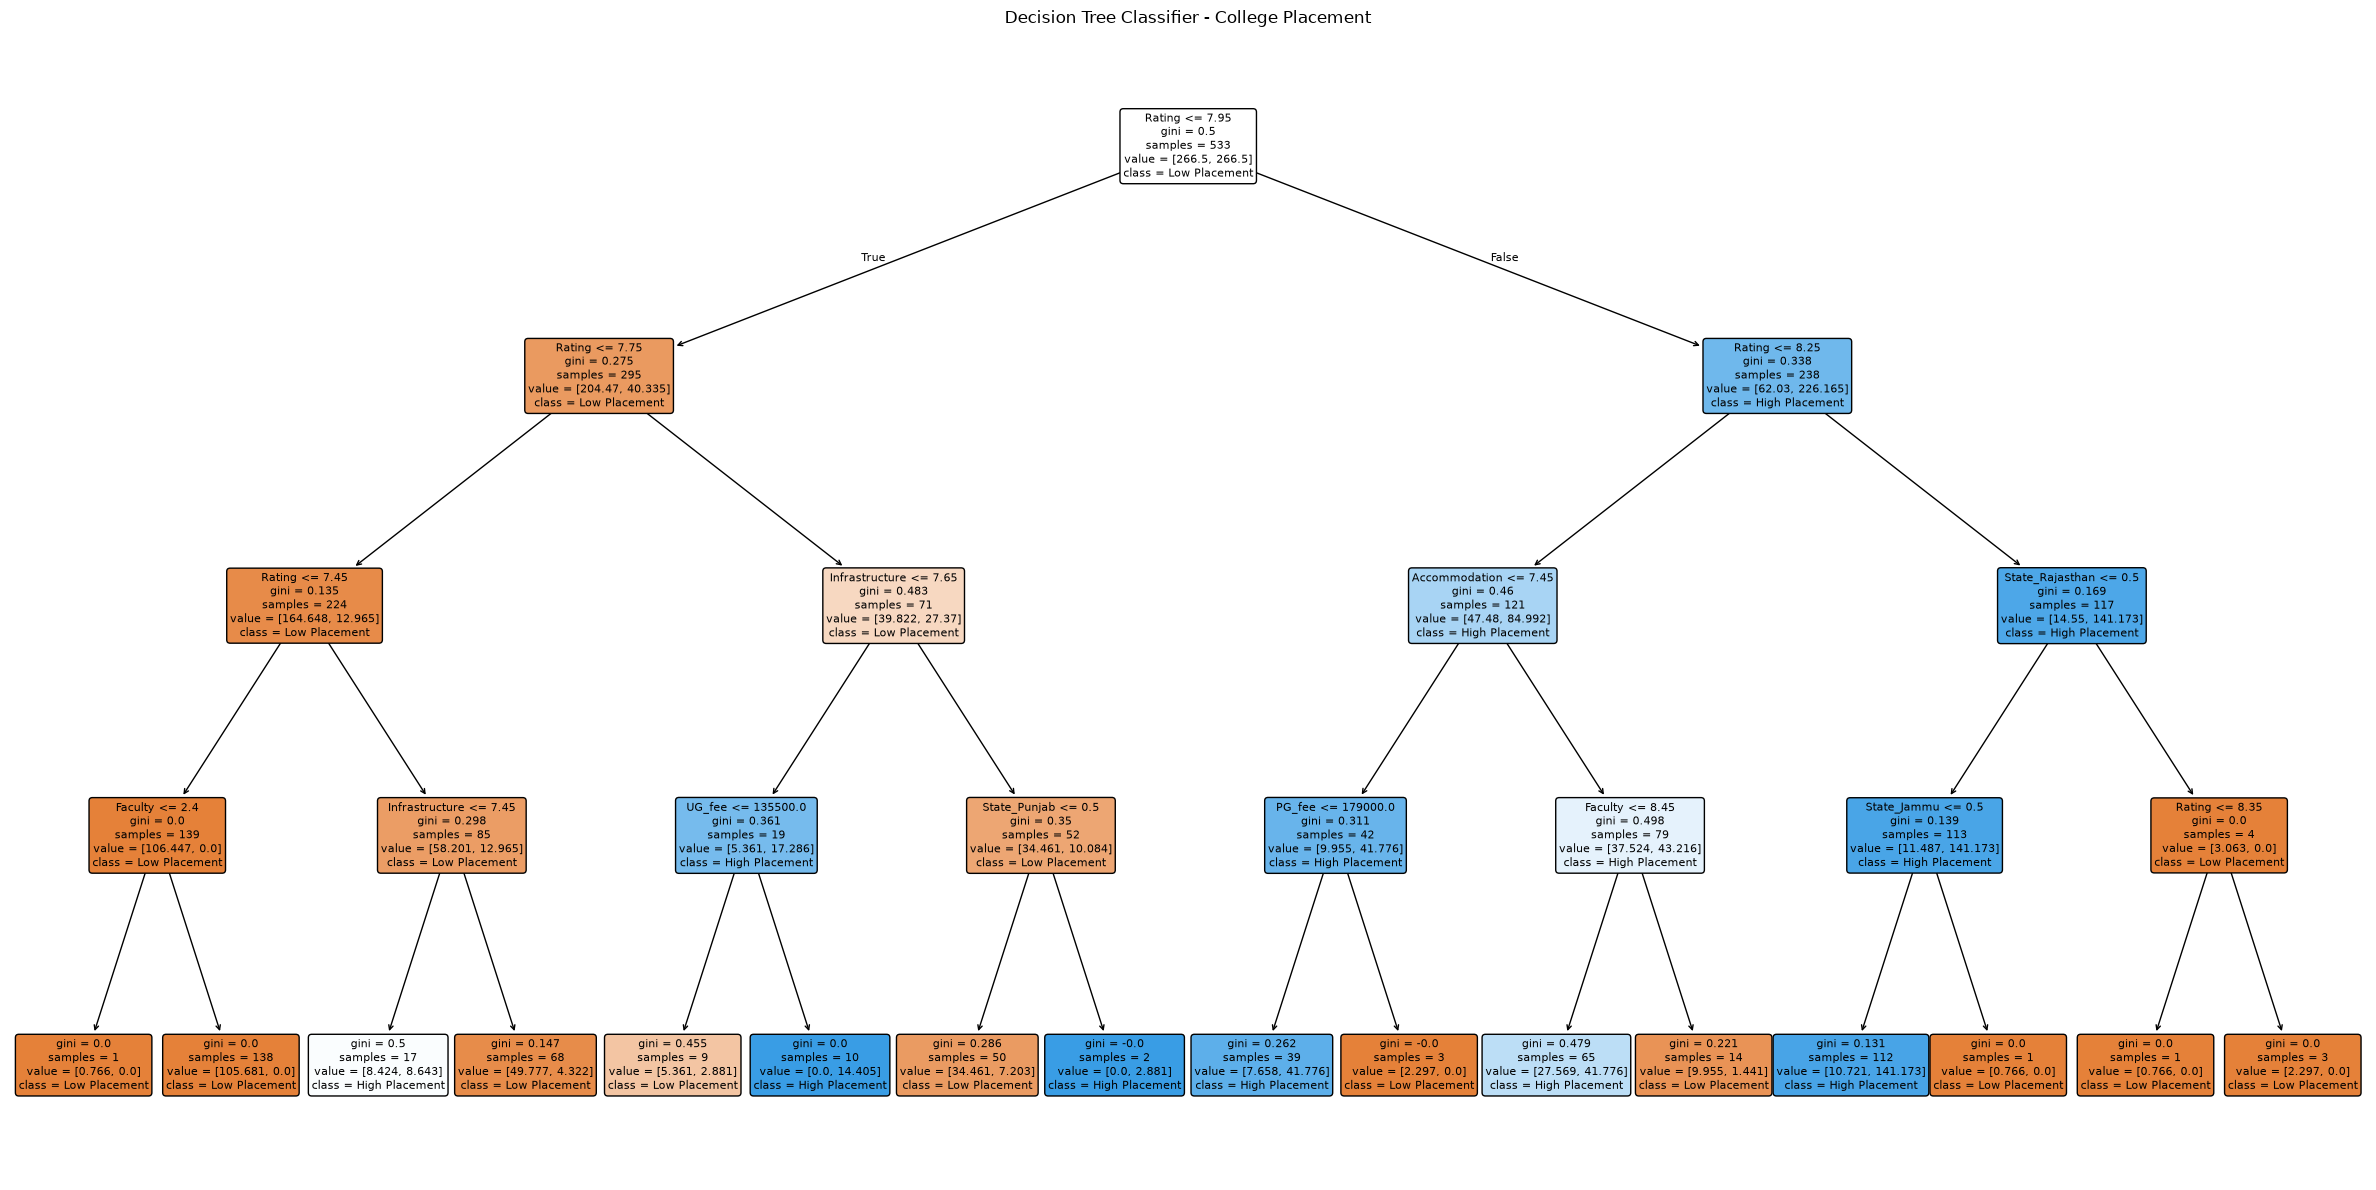

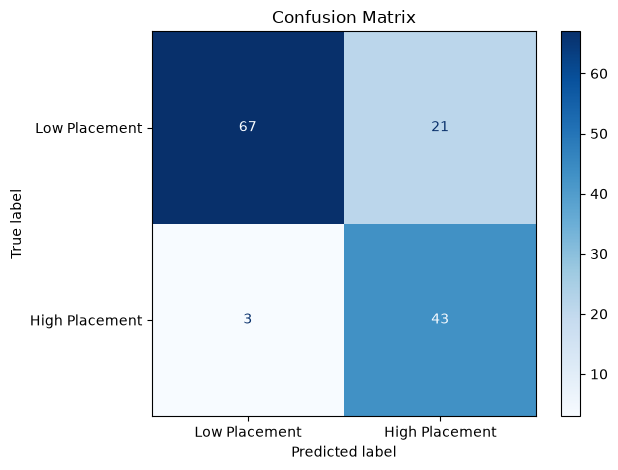

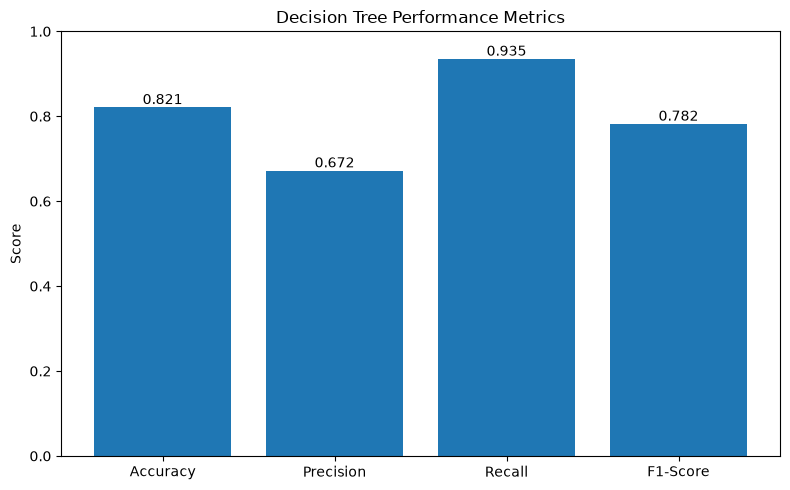

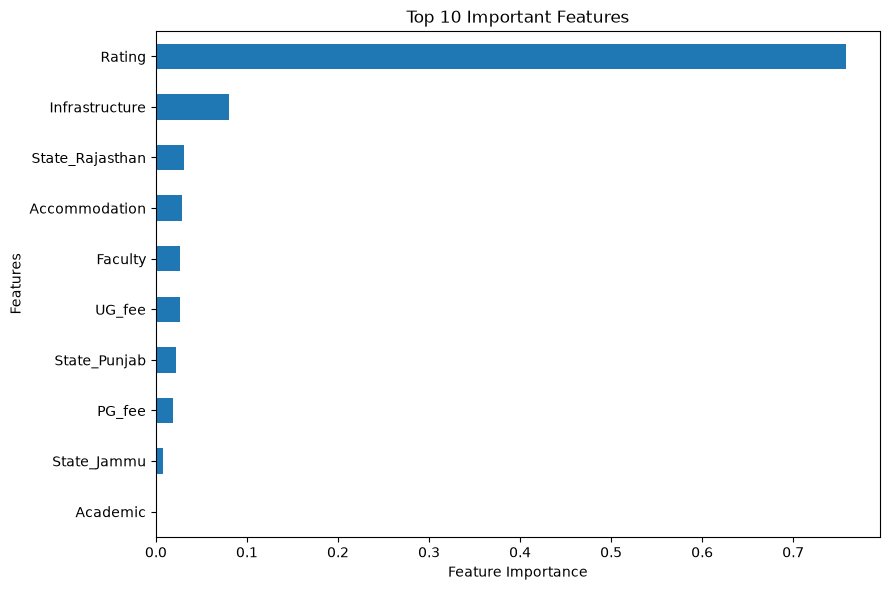

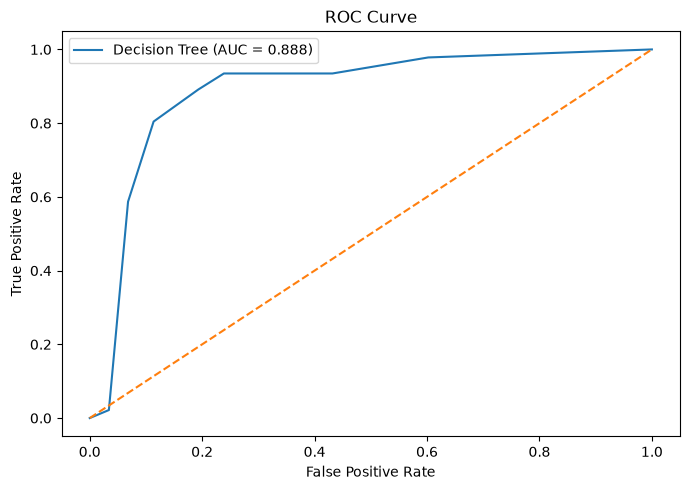

ROC-AUC Score: 0.8883

Sample Predictions:
      Actual_Status Predicted_Status
438  High Placement   High Placement
725   Low Placement    Low Placement
190   Low Placement    Low Placement
411   Low Placement    Low Placement
89    Low Placement   High Placement
3    High Placement   High Placement
255  High Placement    Low Placement
10    Low Placement    Low Placement
392   Low Placement    Low Placement
447   Low Placement    Low Placement


In [1]:

# Lab 8: Decision Tree Classifier
# Building, Visualizing, and Evaluating a Decision Tree Model

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

# Step 2: Load the dataset
df = pd.read_csv("Colleges_Dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Information:")
df.info()

# Step 3: Clean the data
# Convert fee and rating columns into numeric values
numeric_columns = [
    "UG_fee", "PG_fee", "Rating", "Academic",
    "Accommodation", "Faculty", "Infrastructure",
    "Placement", "Social_Life"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str)
        .str.replace(",", "", regex=False)
        .str.strip()
        .replace("--", np.nan),
        errors="coerce"
    )

# Remove rows where the target cannot be determined
df = df.dropna(subset=["Placement"]).copy()

# Step 4: Create a binary target variable
# 1 = High Placement, 0 = Low Placement
df["Placement_Status"] = (
    df["Placement"] >= 8.0
).astype(int)

print("\nPlacement Status Distribution:")
print(df["Placement_Status"].value_counts())

# Step 5: Select features and target
# Remove identifiers, college names, and the target-source column
X = df.drop(
    columns=[
        "Unnamed: 0",
        "College_Name",
        "Placement",
        "Placement_Status"
    ],
    errors="ignore"
)

y = df["Placement_Status"]

# Convert categorical State values into numeric dummy variables
X = pd.get_dummies(X, columns=["State"], drop_first=True)

# Replace missing numeric values with their column medians
X = X.fillna(X.median())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

# Step 6: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Step 7: Build and train the Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# Step 8: Make predictions
y_pred = model.predict(X_test)

# Step 9: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, zero_division=0
)
recall = recall_score(
    y_test, y_pred, zero_division=0
)
f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("\n========== MODEL EVALUATION ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Low Placement", "High Placement"],
        zero_division=0
    )
)

# Step 10: Visualize the Decision Tree
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Low Placement", "High Placement"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier - College Placement")
plt.tight_layout()
plt.show()

# Step 11: Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Placement", "High Placement"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# Step 12: Performance Metrics Bar Chart
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Decision Tree Performance Metrics")
plt.bar_label(bars, fmt="%.3f")
plt.tight_layout()
plt.show()

# Step 13: Feature Importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

top_features = importance.head(10).sort_values()

plt.figure(figsize=(9, 6))
top_features.plot(kind="barh")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.show()

# Step 14: ROC Curve and AUC
if len(np.unique(y_test)) == 2:
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.figure(figsize=(7, 5))
    plt.plot(
        fpr, tpr,
        label=f"Decision Tree (AUC = {auc_score:.3f})"
    )
    plt.plot([0, 1], [0, 1], linestyle="--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"ROC-AUC Score: {auc_score:.4f}")

# Step 15: Display sample predictions
results = pd.DataFrame({
    "Actual_Status": y_test.map({
        0: "Low Placement",
        1: "High Placement"
    }),
    "Predicted_Status": pd.Series(
        y_pred, index=y_test.index
    ).map({
        0: "Low Placement",
        1: "High Placement"
    })
})

print("\nSample Predictions:")
print(results.head(10))
